(12778, 1919)
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_validation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_validation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_validation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_validation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_validation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id  d_1  d_2  d_3  d_4  ...  d_1904  d_1905  d_1906  d_1907  d_1908  \
0       CA    0    0    0    0  ...     1.0     3.0     0.0     1.0     1.0   
1       CA    0    0    0    0  ...     0.0     0.0     0.0     0.0     0.0   
2       CA    0    0    0    0  ...     2.0     1.0     2.0     1.0     1.0   
3       CA    0    0    0    0  ...     1.0     0.0     5.0     4.0     1.0   
4       CA    0    0    0    0  ...     2.0     1.0     1.0     0.0     1.0   

   d_1909  d_1910  d_1911  d_1

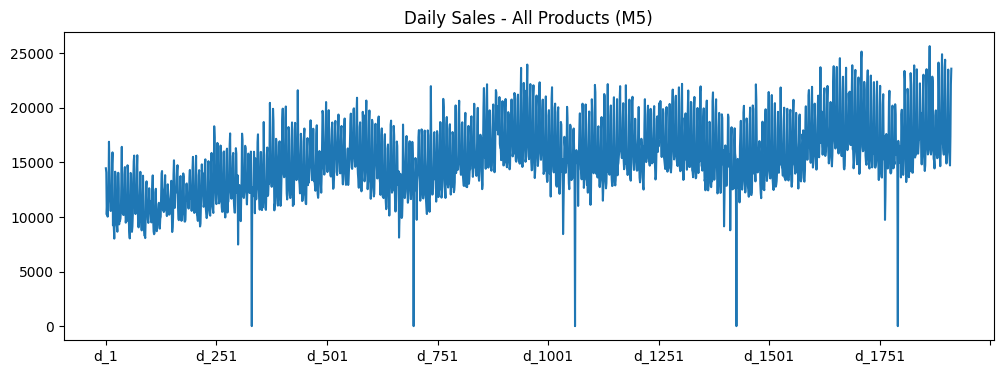

dept_id
FOODS_3        13872630.0
HOUSEHOLD_1     4903293.0
HOBBIES_1       3213207.0
FOODS_2         2957744.0
FOODS_1         2365928.0
HOUSEHOLD_2     1554347.0
HOBBIES_2        255760.0
Name: total_sales, dtype: float64


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load M5 file
df = pd.read_csv('sales_train_validation.csv')
print(df.shape)
print(df.head())

# M5 is WIDE format: d_1, d_2, ... d_1913 are days
# Let's see columns
print("Stores:", df['store_id'].nunique())
print("Products:", df['item_id'].nunique())
print("Categories:", df['cat_id'].unique())

# 2. Total sales per day - sum across all products
# Get only day columns
day_cols = [c for c in df.columns if c.startswith('d_')]
daily = df[day_cols].sum()

daily.plot(figsize=(12,4), title='Daily Sales - All Products (M5)')
plt.show()

# 3. Top selling departments
# Sum each product's total sales
df['total_sales'] = df[day_cols].sum(axis=1)
print(df.groupby('dept_id')['total_sales'].sum().sort_values(ascending=False))

In [3]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
import xgboost as xgb

# 1. Load calendar
cal = pd.read_csv('calendar.csv')
print(cal.head())

# 2. Pick ONE product to start - top seller from FOODS_3
# Let's take first FOODS_3 item in CA_1
sample = df[(df['store_id']=='CA_1') & (df['dept_id']=='FOODS_3')].iloc[0]
print("Training on:", sample['item_id'])

# 3. Melt wide -> long format (like Oracle OTBI export)
day_cols = [c for c in df.columns if c.startswith('d_')]
sales_long = sample[day_cols].T.reset_index()
sales_long.columns = ['d', 'sales']
# Convert sales to numeric to ensure all calculated lags and rolling features are numeric
sales_long['sales'] = pd.to_numeric(sales_long['sales'], errors='coerce')

sales_long = sales_long.merge(cal[['d', 'date', 'wday', 'month', 'year', 'event_name_1']], on='d', how='left')
sales_long['date'] = pd.to_datetime(sales_long['date'])

# 4. Create SCM Features - THIS IS THE KEY PART
sales_long['lag_7'] = sales_long['sales'].shift(7)
sales_long['lag_28'] = sales_long['sales'].shift(28)
sales_long['rolling_mean_7'] = sales_long['sales'].shift(7).rolling(7).mean()
sales_long['rolling_mean_28'] = sales_long['sales'].shift(28).rolling(28).mean()

# Drop NaN from lags
sales_long = sales_long.dropna()
print(sales_long.head())

# 5. Train / Test Split - Last 28 days = test (like real forecast)
train = sales_long[:-28]
test = sales_long[-28:]

features = ['wday', 'month', 'year', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28']
model = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6)
model.fit(train[features], train['sales'])

pred = model.predict(test[features])
rmse = np.sqrt(mean_squared_error(test['sales'], pred))
print(f"RMSE for 28-day forecast: {rmse:.2f}")
print("Actual:", test['sales'].values[:7])
print("Predicted:", pred[:7].round(1))

         date  wm_yr_wk    weekday  wday  month  year    d event_name_1  \
0  2011-01-29     11101   Saturday     1      1  2011  d_1          NaN   
1  2011-01-30     11101     Sunday     2      1  2011  d_2          NaN   
2  2011-01-31     11101     Monday     3      1  2011  d_3          NaN   
3  2011-02-01     11101    Tuesday     4      2  2011  d_4          NaN   
4  2011-02-02     11101  Wednesday     5      2  2011  d_5          NaN   

  event_type_1 event_name_2 event_type_2  snap_CA  snap_TX  snap_WI  
0          NaN          NaN          NaN        0        0        0  
1          NaN          NaN          NaN        0        0        0  
2          NaN          NaN          NaN        0        0        0  
3          NaN          NaN          NaN        1        1        0  
4          NaN          NaN          NaN        1        0        1  
Training on: FOODS_3_001
         d  sales       date  wday  month  year    event_name_1  lag_7  \
85    d_86      3 2011-04-24  

          item_id     total
2314  FOODS_3_090  127203.0
2810  FOODS_3_586   87691.0
2476  FOODS_3_252   74971.0
2344  FOODS_3_120   61899.0
2937  FOODS_3_714   54080.0
Now training on BEST seller: FOODS_3_090


/tmp/ipykernel_2654/414911853.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train[features] = train[features].astype(float)
/tmp/ipykernel_2654/414911853.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test[features] = test[features].astype(float)



RMSE for 28-day forecast: 32.39
Mean daily sales: 71.97
Actual: [ 52 116   0   0  39  63 124]
Predicted: [66.2 92.8  5.8 40.4 70.8 68.6 90.5]


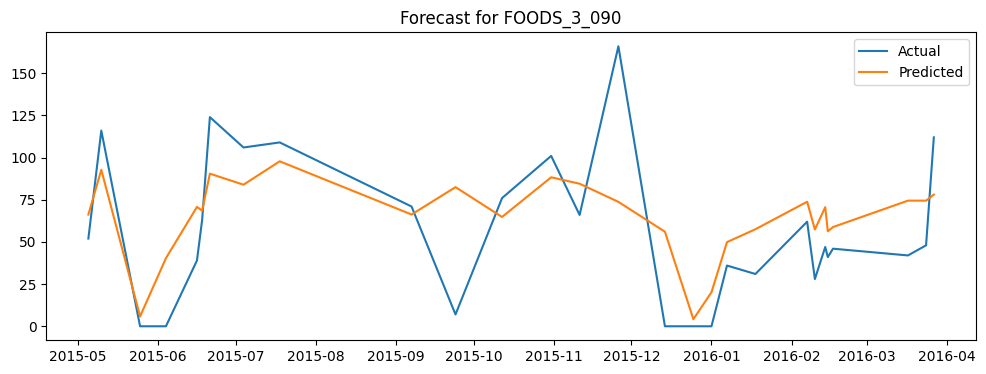

In [5]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
import xgboost as xgb

day_cols = [c for c in df.columns if c.startswith('d_')]
subset = df[(df['store_id']=='CA_1') & (df['dept_id']=='FOODS_3')].copy()
subset['total'] = subset[day_cols].sum(axis=1)
subset = subset.sort_values('total', ascending=False)
print(subset[['item_id','total']].head(5))

top_item = subset.iloc[0]['item_id']
print("Now training on BEST seller:", top_item)

sample = subset.iloc[0]
cal = pd.read_csv('calendar.csv')

sales_long = sample[day_cols].T.reset_index()
sales_long.columns = ['d', 'sales']

# *** THE FIX ***
sales_long['sales'] = pd.to_numeric(sales_long['sales'], errors='coerce')

sales_long = sales_long.merge(cal[['d', 'date', 'wday', 'month', 'year', 'event_name_1', 'snap_CA']], on='d', how='left')
sales_long['date'] = pd.to_datetime(sales_long['date'])

sales_long['is_event'] = sales_long['event_name_1'].notna().astype(int)
sales_long['lag_7'] = sales_long['sales'].shift(7)
sales_long['lag_28'] = sales_long['sales'].shift(28)
sales_long['rolling_mean_7'] = sales_long['sales'].shift(7).rolling(7).mean()
sales_long['rolling_mean_28'] = sales_long['sales'].shift(28).rolling(28).mean()
sales_long = sales_long.dropna()

train = sales_long[:-28]
test = sales_long[-28:]

features = ['wday', 'month', 'year', 'is_event', 'snap_CA', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28']

# Force all features to float too
train[features] = train[features].astype(float)
test[features] = test[features].astype(float)

model = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6)
model.fit(train[features], train['sales'])

pred = model.predict(test[features])
pred = np.maximum(pred, 0)

rmse = np.sqrt(mean_squared_error(test['sales'], pred))
print(f"\nRMSE for 28-day forecast: {rmse:.2f}")
print("Mean daily sales:", train['sales'].mean().round(2))
print("Actual:", test['sales'].values[:7])
print("Predicted:", pred[:7].round(1))

import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
plt.plot(test['date'], test['sales'], label='Actual')
plt.plot(test['date'], pred, label='Predicted')
plt.legend()
plt.title(f'Forecast for {top_item}')
plt.show()

Training on: FOODS_3_090
prices shape: (3384457, 4)
cal shape: (1969, 14)
After calendar merge: 1913
Price rows for this product: 282
After price merge: 1913
NaN prices: 0
After lag dropna: 1858
Train: 1830 Test: 28

OLD RMSE: 32.39
NEW RMSE with Price: 28.01
Actual: [25 47 23 21 72 58 54]
Predicted: [54.4 49.6 56.1 55.6 59.1 68.9 94.2]

What drives demand?
lag_7              0.209442
sell_price         0.207997
rolling_mean_7     0.145354
month              0.091717
rolling_mean_28    0.068263
wday               0.066314
year               0.066037
lag_28             0.058149
snap_CA            0.045163
is_event           0.041565
dtype: float32


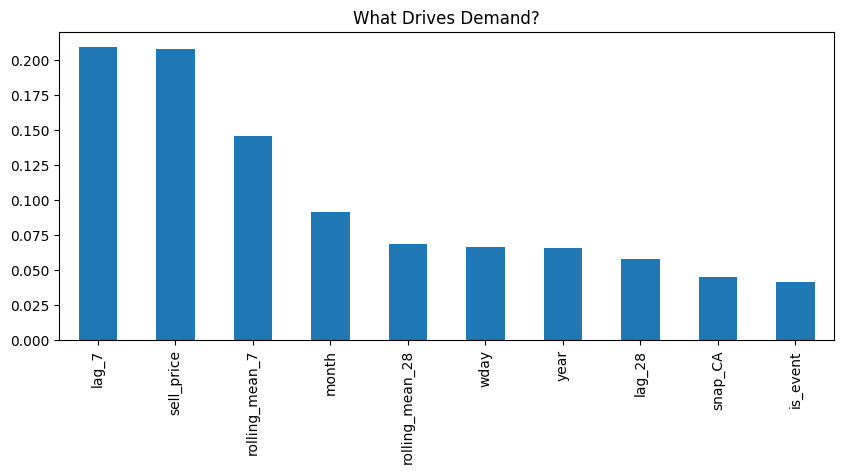

In [8]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
import xgboost as xgb
import matplotlib.pyplot as plt

# 1. REBUILD from scratch - don't reuse old sales_long
day_cols = [c for c in df.columns if c.startswith('d_')]
subset = df[(df['store_id']=='CA_1') & (df['dept_id']=='FOODS_3')].copy()
subset['total'] = subset[day_cols].sum(axis=1)
subset = subset.sort_values('total', ascending=False)
top_item = subset.iloc[0]['item_id']
print("Training on:", top_item)

sample = subset.iloc[0]
cal = pd.read_csv('calendar.csv')
prices = pd.read_csv('sell_prices.csv')
print("prices shape:", prices.shape)
print("cal shape:", cal.shape)

sales_long2 = sample[day_cols].T.reset_index()
sales_long2.columns = ['d', 'sales']
sales_long2['sales'] = pd.to_numeric(sales_long2['sales'], errors='coerce')

# Merge calendar
sales_long2 = sales_long2.merge(cal[['d', 'date', 'wday', 'month', 'year', 'event_name_1', 'snap_CA', 'wm_yr_wk']], on='d', how='left')
sales_long2['date'] = pd.to_datetime(sales_long2['date'])
print("After calendar merge:", len(sales_long2))

# Merge price - ONLY this product + store
p = prices[(prices['store_id']=='CA_1') & (prices['item_id']==top_item)]
print("Price rows for this product:", len(p))
sales_long2 = sales_long2.merge(p[['wm_yr_wk','sell_price']], on='wm_yr_wk', how='left')
print("After price merge:", len(sales_long2))
print("NaN prices:", sales_long2['sell_price'].isna().sum())

# FIX: Fill price instead of dropna
sales_long2['sell_price'] = sales_long2['sell_price'].ffill().bfill()

# Features
sales_long2['is_event'] = sales_long2['event_name_1'].notna().astype(int)
sales_long2['lag_7'] = sales_long2['sales'].shift(7)
sales_long2['lag_28'] = sales_long2['sales'].shift(28)
sales_long2['rolling_mean_7'] = sales_long2['sales'].shift(7).rolling(7).mean()
sales_long2['rolling_mean_28'] = sales_long2['sales'].shift(28).rolling(28).mean()
sales_long2['price_change'] = sales_long2['sell_price'].pct_change().fillna(0)

# FIX: Only drop NaN from lags, not from whole df
sales_long2 = sales_long2.dropna(subset=['lag_7','lag_28','rolling_mean_7','rolling_mean_28'])
print("After lag dropna:", len(sales_long2))

train2 = sales_long2[:-28].copy()
test2 = sales_long2[-28:].copy()
print("Train:", len(train2), "Test:", len(test2))

features2 = ['wday', 'month', 'year', 'is_event', 'snap_CA', 'sell_price', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28']

model2 = xgb.XGBRegressor(n_estimators=800, learning_rate=0.03, max_depth=6)
model2.fit(train2[features2].astype(float), train2['sales'].astype(float))

pred2 = np.maximum(model2.predict(test2[features2].astype(float)), 0)
rmse2 = np.sqrt(mean_squared_error(test2['sales'], pred2))
print(f"\nOLD RMSE: 32.39")
print(f"NEW RMSE with Price: {rmse2:.2f}")
print("Actual:", test2['sales'].values[:7])
print("Predicted:", pred2[:7].round(1))

importances = pd.Series(model2.feature_importances_, index=features2).sort_values(ascending=False)
print("\nWhat drives demand?")
print(importances)
importances.plot(kind='bar', figsize=(10,4), title='What Drives Demand?')
plt.show()

In [9]:
import pickle

# Save model
with open('xgb_model.pkl', 'wb') as f:
    pickle.dump(model2, f)

# Save last 28 days forecast for dashboard
forecast_df = test2[['date','sales']].copy()
forecast_df['predicted'] = pred2
forecast_df.to_csv('forecast_28_days.csv', index=False)
print(forecast_df.head())
print("Saved!")


           date  sales  predicted
1885 2016-03-28     25  54.391090
1886 2016-03-29     47  49.577324
1887 2016-03-30     23  56.122730
1888 2016-03-31     21  55.644421
1889 2016-04-01     72  59.073433
Saved!
